## Setup & Instalasi

Package yang kita butuhkan:
- `langchain`, `langchain-community`, `langchain-text-splitters` — framework utama
- `langchain-google-genai` — untuk Google Embedding
- `langchain-groq` — untuk LLM Llama via Groq
- `faiss-cpu` — vector database
- `PyMuPDF` — baca file PDF
- `langgraph` — orkestrasi alur RAG


In [ ]:
!pip install -qU langchain langchain-community langchain-text-splitters faiss-cpu langchain-google-genai PyMuPDF langchain-groq langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.9/132.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.2/246.2 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests=

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [164]:
import os
from google.colab import userdata
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_groq import ChatGroq

os.environ["GOOGLE_API_KEY"] = userdata.get('GEMINI')
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')
os.environ["SEMANTIC_SCHOLAR_API_KEY"] = userdata.get('SEMANTIC_SCHOLAR_API_KEY')

embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2", output_dimensionality=768)

llm = ChatGroq(
    temperature=0,
    model='llama-3.3-70b-versatile'
)

In [165]:
import fitz
import re
import time
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field

# 1. Definisikan Skema Data yang WAJIB dipatuhi oleh LLM
class PaperMetadata(BaseModel):
    author: str = Field(description="Nama belakang (family name) dari penulis pertama dengan huruf kecil. Isi 'unknown' jika tidak ditemukan.")
    year: int = Field(description="Tahun terbit jurnal (4 angka). Isi 0 jika tidak ditemukan.")

def extract_metadata_with_llm(pdf_path, llm):
    """Mengekstrak metadata dengan LangChain Structured Output (100% Anti-Gagal Parsing)"""
    try:
        doc = fitz.open(pdf_path)
        # Batasi 1000 karakter saja untuk menghindari Groq Token Limit (TPM)
        first_page_text = doc[0].get_text("text")[:1000]

        # 2. Paksa LLM menggunakan format Pydantic
        structured_llm = llm.with_structured_output(PaperMetadata)

        prompt = ChatPromptTemplate.from_template(
            "Kamu adalah asisten ekstraksi data akademik. Ekstrak informasi "
            "dari teks halaman pertama jurnal berikut:\n\n{text}"
        )

        chain = prompt | structured_llm

        # Jeda 3 detik agar aman dari pemblokiran API Groq (Rate Limit)
        time.sleep(3)

        # 3. Invoke langsung menghasilkan objek Pydantic, bukan teks mentah!
        response = chain.invoke({"text": first_page_text})

        # 4. Ubah ke Dictionary standar
        metadata = {
            "author": response.author.lower(),
            "year": response.year,
            "source_file": pdf_path.split('/')[-1]
        }
        if metadata["year"] == 0:
            import re
            year_match = re.search(r'\b(19|20)\d{2}\b', first_page_text)
            if year_match:
                metadata["year"] = int(year_match.group())

        return metadata

    except Exception as e:
        print(f" Gagal mengekstrak metadata dari {pdf_path}: {e}")
        return {"author": "unknown", "year": 0, "source_file": pdf_path.split('/')[-1]}

def extract_citation_from_sentence(sentence):
    """Mendeteksi sitasi (Penulis, Tahun) dalam kalimat menggunakan RegEx."""
    pattern = r"\(([A-Za-z\s]+)(?:\s*dkk\.)?,\s*(\d{4})\)"
    matches = re.findall(pattern, sentence)

    if matches:
        return {"has_citation": True, "author": matches[0][0].strip().lower(), "year": int(matches[0][1])}
    else:
        return {"has_citation": False, "author": None, "year": None}

In [ ]:
import os
import fitz
from langchain_text_splitters import RecursiveCharacterTextSplitter

FOLDER_REFERENSI = "/content/drive/MyDrive/folder knowledge base rag"

def prepare_document_chunks(folder_path, llm):
    """Fungsi mandiri untuk ekstraksi dan chunking tanpa menyentuh FAISS/Embedding"""
    all_chunks = []
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=1000,
        chunk_overlap=200,
        separators=["\n\n", "\n", r"(?<=\. )", " ", ""]
    )

    pdf_files = [f for f in os.listdir(folder_path) if f.endswith(".pdf")]

    for filename in pdf_files:
        file_path = os.path.join(folder_path, filename)
        print(f"📄 Memproses {filename}...")
        try:
            doc = fitz.open(file_path)
            full_text = "\n".join([page.get_text() for page in doc])

            # Ekstrak metadata via Pydantic/LLM
            metadata = extract_metadata_with_llm(file_path, llm)
            print(f"   -> Metadata: {metadata['author']} ({metadata['year']})")

            chunks = splitter.create_documents(texts=[full_text], metadatas=[metadata])
            all_chunks.extend(chunks)
        except Exception as e:
            print(f" Error pada {filename}: {e}")

    print(f"\n Selesai! Total {len(all_chunks)} chunks siap di-embed.")
    return all_chunks

dokumen_siap_embed = prepare_document_chunks(FOLDER_REFERENSI, llm)

📄 Memproses sustainability-15-01906-v2.pdf...
   -> Metadata: gulzar (2023)
📄 Memproses Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.pdf...
   -> Metadata: sandler (2018)
📄 Memproses 1-s2.0-S1877050924020477-main.pdf...
   -> Metadata: liu (2024)
📄 Memproses 05-AIA3202441_online.pdf...
   -> Metadata: kavita bhosle (2023)
📄 Memproses admin,+kls.v8i1.15622.pdf...
   -> Metadata: winda setya (2024)
📄 Memproses 1704.04861v1.pdf...
   -> Metadata: howard (2017)
📄 Memproses 2304.01524v1.pdf...
   -> Metadata: dey (0)
📄 Memproses Sunfa_Ata_Zuyan_machine_learning_models.pdf...
   -> Metadata: moshayedi (2022)
📄 Memproses fmed-11-1487713.pdf...
   -> Metadata: sathya (2024)
📄 Memproses 1502.03167v3.pdf...
   -> Metadata: ioffe (2015)
📄 Memproses 847-4390-1-PB.pdf...
   -> Metadata: raja pahlefi ray (2025)
📄 Memproses 2404.12948v1.pdf...
   -> Metadata: akhmedova (0)
📄 Memproses 1412.6980v9.pdf...
   -> Metadata: kingma (2015)
📄 Memproses IJCS_14_1+Turihohabwe.pdf...
   -> Metadata: t

In [ ]:
# ==========================================
# CELL: SMART EMBEDDING & FAISS SAVER
# ==========================================
import time
import faiss
import os
from langchain_community.docstore.in_memory import InMemoryDocstore
from langchain_community.vectorstores import FAISS

def embed_and_save_to_faiss(chunks, embeddings, save_path="faiss_index"):
    """
    Fungsi mandiri untuk embedding ke Google Gemini dengan perlindungan berlapis:
    1. Micro-batching (30 chunk/pengiriman)
    2. Incremental Auto-Save (Simpan progress setiap 150 chunk)
    3. Resume Capability (Melanjutkan dari titik terakhir jika program terhenti)
    4. Exponential Backoff (Mundur teratur jika terkena limit Google)
    """
    if not chunks:
        print(" Tidak ada chunk untuk diproses.")
        return None

    print(f"Memulai Pemrosesan {len(chunks)} chunks ke Google Gemini...")

    # --- 1. FITUR RESUME: CEK PROGRESS SEBELUMNYA ---
    if os.path.exists(save_path):
        print(f"Menemukan index FAISS lama di folder '{save_path}'.")
        # Load database lama (wajib allow_dangerous_deserialization=True di LangChain baru)
        vector_store = FAISS.load_local(save_path, embeddings, allow_dangerous_deserialization=True)
        # Hitung ada berapa dokumen yang sudah tersimpan
        start_index = vector_store.index.ntotal
        print(f"   -> Sudah ada {start_index} chunk di database. Melanjutkan dari titik ini...")
    else:
        print("Membuat database FAISS baru dari nol...")
        index = faiss.IndexFlatL2(len(embeddings.embed_query("hello world")))
        vector_store = FAISS(
            embedding_function=embeddings,
            index=index,
            docstore=InMemoryDocstore(),
            index_to_docstore_id={},
        )
        start_index = 0

    # --- 2. PENGATURAN BATCH & RATE LIMIT ---
    batch_size = 30
    i = start_index
    attempt = 0 # Penghitung untuk Exponential Backoff

    # --- 3. LOOPING UTAMA ---
    while i < len(chunks):
        batch = chunks[i : i + batch_size]
        print(f"   -> Embedding chunk {i+1} sampai {min(i+batch_size, len(chunks))}...")

        try:
            # Mencoba memasukkan batch ke FAISS
            vector_store.add_documents(batch)

            # Jika SUKSES:
            i += batch_size
            attempt = 0 # Reset penghitung error karena berhasil

            # --- 4. FITUR AUTO-SAVE ---
            # Simpan ke disk secara otomatis setiap kelipatan 150 chunk atau jika sudah selesai
            if i % 150 == 0 or i >= len(chunks):
                vector_store.save_local(save_path)
                print(f" [AUTO-SAVE] Progress aman! Tersimpan ke disk di chunk {i}.")

            # Jeda aman standar agar tidak diblokir Google
            time.sleep(15)

        except Exception as e:
            error_msg = str(e)

            # Jika GAGAL karena Rate Limit (429 / RESOURCE_EXHAUSTED)
            if "RESOURCE_EXHAUSTED" in error_msg or "429" in error_msg:
                attempt += 1
                # Waktu tunggu eksponensial: 60s, 120s, 180s...
                sleep_time = 60 * attempt

                print(f"Terkena Limit Google (Penalti ke-{attempt}). Istirahat {sleep_time} detik...")
                time.sleep(sleep_time)
                # Catatan: nilai 'i' tidak ditambah, sehingga loop akan mengulang batch yang gagal ini

            else:
                print(f"Error tidak terduga: {error_msg}")
                # Langsung simpan data yang ada sebelum program benar-benar mati
                vector_store.save_local(save_path)
                print(f"[EMERGENCY SAVE] Sebagian data berhasil diamankan sebelum error.")
                break

    print(f"\n Proses Selesai Total! Semua data telah di-embed dan tersimpan di folder: {save_path}/")
    return vector_store

vector_store = embed_and_save_to_faiss(dokumen_siap_embed, embeddings)

Memulai Pemrosesan 1692 chunks ke Google Gemini...
Menemukan index FAISS lama di folder 'faiss_index'.
   -> Sudah ada 1050 chunk di database. Melanjutkan dari titik ini...
   -> Embedding chunk 1051 sampai 1080...
   -> Embedding chunk 1081 sampai 1110...
   -> Embedding chunk 1111 sampai 1140...
   -> Embedding chunk 1141 sampai 1170...
Terkena Limit Google (Penalti ke-1). Istirahat 60 detik...
   -> Embedding chunk 1141 sampai 1170...
   -> Embedding chunk 1171 sampai 1200...
 [AUTO-SAVE] Progress aman! Tersimpan ke disk di chunk 1200.
   -> Embedding chunk 1201 sampai 1230...
   -> Embedding chunk 1231 sampai 1260...
   -> Embedding chunk 1261 sampai 1290...
Terkena Limit Google (Penalti ke-1). Istirahat 60 detik...
   -> Embedding chunk 1261 sampai 1290...
   -> Embedding chunk 1291 sampai 1320...
   -> Embedding chunk 1321 sampai 1350...
 [AUTO-SAVE] Progress aman! Tersimpan ke disk di chunk 1350.
   -> Embedding chunk 1351 sampai 1380...
   -> Embedding chunk 1381 sampai 1410...

In [166]:
# Inisialisasi LLM — pakai Llama 3.3 70B via Groq (gratis, cepat)
# Groq menyediakan inference engine yang sangat cepat untuk model open-source

from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')


MODEL = 'openai/gpt-oss-120b'

llm = ChatGroq(
    temperature=0,  # 0 = deterministik, cocok untuk Q&A faktual
    model=MODEL     # bisa diganti model lain seperti gemini atau GPT
)

In [167]:
from google.colab import files
import fitz
import time
from langchain_text_splitters import RecursiveCharacterTextSplitter

def upload_and_chunk_draft():
    """
    Upload draft skripsi (PDF) dari user, ekstrak teks, dan pecah
    menjadi chunk per paragraf/kalimat untuk dianalisis klaim-nya.
    """
    print("====================================================")
    print("📁 SILAKAN UPLOAD FILE DRAFT SKRIPSI ANDA (PDF)")
    print("====================================================")
    uploaded = files.upload()

    draft_chunks = []
    full_draft_text = ""

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=500,       # Ukuran kecil agar isolasi klaim lebih granular
        chunk_overlap=50,
        separators=["\n\n", "\n", r"(?<=\. )", " ", ""]
    )

    for filename in uploaded.keys():
        print(f"\n📖 Memproses file draf: {filename}...")
        doc = fitz.open(filename)
        full_text = "\n".join([page.get_text() for page in doc])
        full_draft_text += full_text # Simpan teks utuh untuk State LangGraph

        chunks = splitter.create_documents(
            texts=[full_text],
            metadatas=[{"source_file": filename, "type": "draft_skripsi"}]
        )
        draft_chunks.extend(chunks)

    print(f"\n✨ Selesai! Total {len(draft_chunks)} potongan klaim siap dianalisis.")

    # Mengembalikan chunks untuk pemrosesan massal, dan teks utuh untuk obrolan interaktif
    return draft_chunks, full_draft_text

def upload_and_embed_user_papers(vector_store, llm, embeddings, save_path="faiss_index"):
    """
    User upload paper PDF tambahan sebagai referensi baru mendadak.
    Paper diekstrak metadatanya via Llama 3.3, di-chunk, dan dimasukkan
    ke FAISS menggunakan Micro-Batching aman untuk menghindari limit Google.
    """
    print("====================================================")
    print("📚 SILAKAN UPLOAD PAPER REFERENSI TAMBAHAN (PDF)")
    print("====================================================")
    uploaded = files.upload()

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=1000,
        chunk_overlap=200,
        separators=["\n\n", "\n", r"(?<=\. )", " ", ""]
    )

    new_chunks = []
    for filename in uploaded.keys():
        print(f"\n📄 Memproses paper baru: {filename}...")
        try:
            doc = fitz.open(filename)
            full_text = "\n".join([page.get_text() for page in doc])

            # Ekstrak metadata menggunakan model patuh JSON (Llama 3.3)
            metadata = extract_metadata_with_llm(filename, llm)
            print(f"   -> Metadata Berhasil Diekstrak: {metadata['author']} ({metadata['year']})")

            chunks = splitter.create_documents(texts=[full_text], metadatas=[metadata])
            new_chunks.extend(chunks)
        except Exception as e:
            print(f"   ❌ Gagal memproses {filename}: {e}")

    # --- PROSES INJEKSI AMAN KE FAISS ---
    if new_chunks and vector_store is not None:
        print(f"\n⚡ Menanamkan {len(new_chunks)} chunk baru ke Knowledge Base...")

        batch_size = 15 # Menggunakan ukuran batch aman kita
        for i in range(0, len(new_chunks), batch_size):
            batch = new_chunks[i : i + batch_size]
            print(f"   -> Menyisipkan chunk {i+1} sampai {min(i+batch_size, len(new_chunks))}...")

            # Masukkan ke database
            vector_store.add_documents(batch)

            # Auto-Save instan ke disk agar data baru permanen terintegrasi
            vector_store.save_local(save_path)

            if i + batch_size < len(new_chunks):
                time.sleep(20) # Istirahat 20 detik di bawah radar Google

        print(f"\n✅ Sukses! Database telah diperbarui secara permanen di folder '{save_path}/'.")
    else:
        print("\n⚠️ Tidak ada dokumen baru yang valid untuk dimasukkan ke Vector Store.")

    return vector_store

In [168]:
# ==========================================
# CELL: TOOL SEMANTIC SCHOLAR (PRO / API KEY ENABLED)
# ==========================================
import os
import requests
import time
from langchain_core.tools import tool

@tool
def search_semantic_scholar(query: str) -> str:
    """Mencari paper akademik relevan via Semantic Scholar API dengan kecepatan tinggi."""
    url = "https://api.semanticscholar.org/graph/v1/paper/search"
    params = {
        "query": query,
        "limit": 5,
        "fields": "title,authors,year,abstract,externalIds,openAccessPdf,url"
    }

    # Siapkan Header Standar
    headers = {
        "User-Agent": "SkripsiAssistant/2.0 (Contact: user@example.com)"
    }

    # Tarik API Key dari Environment Variable
    api_key = os.environ.get("SEMANTIC_SCHOLAR_API_KEY", "")

    if api_key:
        headers["x-api-key"] = api_key # Header resmi Semantic Scholar
    else:
        print("   ⚠️ Menjalankan Semantic Scholar tanpa API Key (Mode Lambat)")

    # Mekanisme Retry
    for attempt in range(3):
        try:
            # Jeda hanya diaktifkan jika TIDAK memakai API key
            if not api_key:
                time.sleep(2)

            response = requests.get(url, params=params, headers=headers, timeout=15)

            if response.status_code == 429:
                print(f"   ⏳ Terkena limit API, mencoba ulang (Attempt {attempt+1}/3)...")
                time.sleep(3)
                continue

            response.raise_for_status()
            data = response.json()

            papers = data.get("data", [])
            if not papers:
                return "Tidak ditemukan paper relevan dari Semantic Scholar."

            results = []
            for p in papers:
                title = p.get("title", "Tanpa judul")
                authors = ", ".join([a.get("name", "") for a in p.get("authors", [])][:3])
                year = p.get("year", "n/a")
                paper_url = p.get("url", "")

                entry = f"- {title} ({authors}, {year})\n  URL: {paper_url}"
                results.append(entry)

            return "\n\n".join(results)

        except Exception as e:
            if attempt == 2:
                return f"Gagal mengakses Semantic Scholar API: {e}"

In [169]:
from typing import List, TypedDict, Any, Annotated
import operator
from langchain_core.documents import Document

class InteractiveDraftState(TypedDict):
    draft_text: str
    user_query: str
    retrieved_docs: List[Document]
    final_response: str

    # --- TAMBAHAN MEMORI ---
    # Annotated dan operator.add memastikan list ini tidak akan mereset dirinya sendiri
    chat_history: Annotated[list, operator.add]

In [170]:
from langchain_core.prompts import ChatPromptTemplate

evaluator_prompt = ChatPromptTemplate.from_template(
    "Kamu adalah Asisten Akademik. Evaluasi KLAIM INTI pengguna berdasarkan KONTEKS PAPER REFERENSI.\n"
    "Abaikan kata pengantar seperti 'Apakah kalimat pada draft skripsi saya relevan'. Fokus pada SUBSTANSI klaimnya saja.\n\n"

    "RIWAYAT OBROLAN SEBELUMNYA:\n{chat_history}\n\n"
    "KLAIM PENGGUNA: {query}\n\n"
    "KONTEKS PAPER SAAT INI:\n{context}\n\n"

    "ATURAN MENJAWAB:\n"
    "1. Jika KLAIM BENAR didukung konteks: Sebutkan identitas paper (dari SUMBER PAPER) dan berikan bukti.\n"
    "2. Jika KLAIM SALAH/BERTENTANGAN (Konteks membahas variabel yang sama tapi hasilnya beda): Berikan KALIMAT PERBAIKAN.\n"
    "3. JIKA KONTEKS TIDAK RELEVAN SAMA SEKALI DENGAN SUBSTANSI KLAIM: Kamu WAJIB menjawab dengan satu kata ini saja: NOT_RELEVANT\n"
    "4. JIKA PERTANYAAN LANJUTAN (misal: 'pada paper mana?'): Jawab menggunakan RIWAYAT OBROLAN, abaikan konteks saat ini jika kosong.\n"
    "5. Jangan generate kode.\n"
)

In [178]:
# ==========================================
# CELL 3: DEFINISI NODE & ROUTING
# ==========================================
from typing import Literal

def retrieve_node(state: InteractiveDraftState):
    query = state["user_query"]
    if 'vector_store' in globals() and vector_store:
        docs = vector_store.similarity_search(query, k=3)
    else:
        docs = []
    return {"retrieved_docs": docs}

def evaluate_node(state: InteractiveDraftState):
    docs = state["retrieved_docs"]
    query = state["user_query"]

    history_list = state.get("chat_history", [])
    history_text = "\n".join([f"{msg['role']}: {msg['content']}" for msg in history_list])

    if not docs and not history_list:
        return {"final_response": "Tidak ditemukan paper referensi"}

    docs_content = "\n\n".join([
        f"SUMBER PAPER: {d.metadata.get('author', 'Penulis Tidak Diketahui')} ({d.metadata.get('year', 'Tahun Tidak Diketahui')})\n"
        f"TEKS: {d.page_content}"
        for d in docs
    ])

    evaluator_chain = evaluator_prompt | llm
    response = evaluator_chain.invoke({
        "query": query,
        "context": docs_content,
        "chat_history": history_text
    })
    llm_output = response.content.strip()

    # PERBAIKAN KRUSIAL: Exact Match. Hanya trigger jika LLM benar-benar menjawab 1 kata itu saja.
    if llm_output == "NOT_RELEVANT" or llm_output.startswith("NOT_RELEVANT"):
        return {"final_response": "NOT_RELEVANT"}

    return {
        "final_response": llm_output,
        "chat_history": [{"role": "User", "content": query}, {"role": "Asisten", "content": llm_output}]
    }

def external_search_node(state: InteractiveDraftState):
    query = state["user_query"]
    draft = state.get("draft_text", "")

    print("   -> Menganalisis klaim dari draft dan memformulasikan kata kunci pencarian...")

    # 1. PROMPT UNTUK EKSTRAKSI KATA KUNCI
    keyword_prompt = ChatPromptTemplate.from_template(
        "Kamu adalah pustakawan akademik senior. Tugasmu mengekstrak VARIABEL INTI dari Pertanyaan User.\n"
        "Jika user merujuk pada draft skripsinya, cari variabel tersebut di TEKS DRAFT.\n"
        "Ubah variabel tersebut menjadi maksimal 4 KATA KUNCI PENCARIAN JURNAL (WAJIB DALAM BAHASA INGGRIS untuk hasil terbaik).\n\n"
        "TEKS DRAFT: {draft}\n"
        "PERTANYAAN USER: {query}\n\n"
        "ATURAN: HANYA keluarkan kata kuncinya saja. Tidak boleh ada kalimat pengantar. Contoh output: moon phase ocean tides"
    )

    # Batasi teks draft maksimal 3000 karakter agar tidak boros token LLM
    keyword_chain = keyword_prompt | llm
    search_keywords = keyword_chain.invoke({
        "query": query,
        "draft": draft[:3000] if draft else "Draft tidak tersedia"
    }).content.strip()

    # Hapus tanda kutip jika LLM bandel menambahkannya
    search_keywords = search_keywords.replace('"', '').replace("'", "")

    print(f"   -> Keyword Akademis yang dikirim ke API: '{search_keywords}'")

    # 2. PANGGIL API MENGGUNAKAN KEYWORD MATANG
    search_result = search_semantic_scholar.invoke(search_keywords)

    response_msg = (
        f"⚠️ Tidak ditemukan paper pendukung di database internal yang secara spesifik membahas klaim tersebut.\n\n"
        f"🔍 **Berikut hasil pencarian alternatif dari Semantic Scholar (berdasarkan keyword: *{search_keywords}*):**\n\n{search_result}\n\n"
        f"Jika salah satu paper di atas sesuai, beri tahu saya judulnya agar saya bisa merekamnya atau silakan upload PDF referensi Anda sendiri."
    )

    return {
        "final_response": response_msg,
        "chat_history": [
            {"role": "User", "content": query},
            {"role": "Asisten", "content": response_msg}
        ]
    }
# --- 5. ROUTING ---
def route_after_evaluate(state: InteractiveDraftState) -> Literal["external_search", "__end__"]:
    if state["final_response"] in ["Tidak ditemukan paper referensi", "NOT_RELEVANT"]:
        return "external_search"
    return "__end__"

In [179]:
from langgraph.graph import START, END, StateGraph
from langgraph.checkpoint.memory import MemorySaver

# 1. Inisialisasi Graph & Memori
workflow = StateGraph(InteractiveDraftState)
memory = MemorySaver() # Mengaktifkan database memori lokal

# 2. Tambahkan Node & Edge (seperti biasa)
workflow.add_node("retrieve", retrieve_node)
workflow.add_node("evaluate", evaluate_node)
workflow.add_node("external_search", external_search_node)
workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "evaluate")
workflow.add_conditional_edges(
    "evaluate",
    route_after_evaluate,
    {"external_search": "external_search", "__end__": END}
)
workflow.add_edge("external_search", END)

# 3. Kompilasi dengan Memory
interactive_app = workflow.compile(checkpointer=memory)

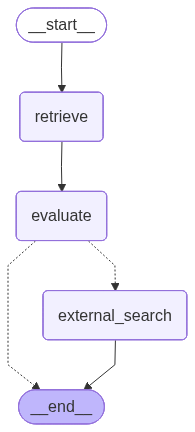

In [180]:
# Visualisasi alur graph
from IPython.display import Image, display

display(Image(interactive_app.get_graph().draw_mermaid_png()))

In [158]:
print("=== SELAMAT DATANG DI ASISTEN VERIFIKASI SKRIPSI ===")
# Panggil fungsi dari Modul 1
draft_chunks, teks_draf_utuh = upload_and_chunk_draft()

# Buat Kunci Sesi Obrolan (Agar asisten punya memori)
config_sesi = {"configurable": {"thread_id": "sesi_bimbingan_01"}}

=== SELAMAT DATANG DI ASISTEN VERIFIKASI SKRIPSI ===
📁 SILAKAN UPLOAD FILE DRAFT SKRIPSI ANDA (PDF)



✨ Selesai! Total 0 potongan klaim siap dianalisis.


In [185]:
query_user = "Apakah kalimat pada draft skripsi saya ini relevan: kecepatan angin tidak berpengaruh sama sekali dalam keputusan melaut nelayan"

print(f" User: {query_user}\n")

# Eksekusi LangGraph
hasil = interactive_app.invoke(
    {"draft_text": teks_draf_utuh, "user_query": query_user},
    config=config_sesi
)
print(f"Asisten: {hasil['final_response']}")

 User: Apakah kalimat pada draft skripsi saya ini relevan: kecepatan angin tidak berpengaruh sama sekali dalam keputusan melaut nelayan

Asisten: Klaim tidak benar.

**Kalimat perbaikan:**  
“Kecepatan angin memang memengaruhi keputusan melaut nelayan; misalnya, Kurup (2024) melaporkan bahwa kondisi angin yang heterogen di pesisir barat daya India secara signifikan memengaruhi aktivitas perikanan perahu kecil dan menuntut prakiraan angin terlokalisasi agar nelayan dapat menentukan kapan aman melaut.”


In [184]:
query_user = "Apakah kalimat pada draft skripsi saya tentang tinggi gelombang itu relevan dengan paper yang ada?"

print(f" User: {query_user}\n")

# Eksekusi LangGraph
hasil = interactive_app.invoke(
    {"draft_text": teks_draf_utuh, "user_query": query_user},
    config=config_sesi
)
print(f"Asisten: {hasil['final_response']}")

 User: Apakah kalimat pada draft skripsi saya tentang tinggi gelombang itu relevan dengan paper yang ada?

Asisten: Klaim benar.  

**Paper:** IrvanA (2024)  

**Bukti singkat:** IrvanA (2024) melaporkan bahwa “fishing vessels can operate effectively in sea states with wave heights up to 3 meters, or sea state 5 and below,” serta menyatakan bahwa pada sea state 5 (gelombang ≈ 3 m) kinerja kapal menurun namun tetap dapat beroperasi.


In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import fitz
import uuid
import time

gr.close_all()
# Variabel global untuk menyimpan teks draft skripsi yang sedang diunggah di UI
global_draft_text = ""

# --- 1. ADAPTOR UPLOAD DRAFT ---
def gradio_upload_draft(file_obj):
    global global_draft_text
    if file_obj is None:
        return "⚠️ Harap masukkan file PDF."

    try:
        doc = fitz.open(file_obj.name)
        global_draft_text = "\n".join([page.get_text() for page in doc])
        return f"✅ Draft Skripsi '{file_obj.name.split('/')[-1]}' berhasil diproses! Siap untuk dianalisis."
    except Exception as e:
        return f"❌ Gagal membaca PDF: {str(e)}"

# --- 2. ADAPTOR UPLOAD PAPER REFERENSI ---
def gradio_upload_refs(file_objs):
    if not file_objs:
        return "⚠️ Harap masukkan minimal 1 file PDF."

    try:
        from langchain_text_splitters import RecursiveCharacterTextSplitter
        splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
        new_chunks = []

        for f in file_objs:
            doc = fitz.open(f.name)
            full_text = "\n".join([page.get_text() for page in doc])

            # Memanggil fungsi ekstraksi metadata Anda yang sudah ada
            # Pastikan llm dan extract_metadata_with_llm sudah terdefinisi di cell atas
            metadata = extract_metadata_with_llm(f.name, llm)

            chunks = splitter.create_documents(texts=[full_text], metadatas=[metadata])
            new_chunks.extend(chunks)

        # Injeksi aman ke FAISS (Micro-batching)
        if new_chunks and 'vector_store' in globals() and vector_store:
            batch_size = 15
            for i in range(0, len(new_chunks), batch_size):
                batch = new_chunks[i : i + batch_size]
                vector_store.add_documents(batch)
                vector_store.save_local("faiss_index")
                if i + batch_size < len(new_chunks):
                    time.sleep(20) # Jeda aman Google API

            return f"✅ Sukses! {len(new_chunks)} potongan dari {len(file_objs)} paper berhasil ditambahkan ke Knowledge Base secara permanen."
        else:
            return "⚠️ Gagal: Vector store belum diinisialisasi."
    except Exception as e:
        return f"❌ Error saat memproses paper: {str(e)}"

# --- 3. ADAPTOR CHATBOT (OTAK LANGGRAPH) ---
# Generate ID Sesi unik setiap kali UI diload agar memori tidak bercampur
session_id = f"sesi_ui_{uuid.uuid4().hex[:8]}"

def gradio_chat(user_message, history):
    global global_draft_text

    config_sesi = {"configurable": {"thread_id": session_id}}

    try:
        # Panggil otak LangGraph
        hasil = interactive_app.invoke(
            {"draft_text": global_draft_text, "user_query": user_message},
            config=config_sesi
        )
        return hasil['final_response']
    except Exception as e:
        return f"🚨 Terjadi kesalahan pada sistem agen: {str(e)}"

# ==========================================
# 4. MEMBANGUN TATA LETAK VISUAL (LAYOUT)
# ==========================================
# Perbaikan Warning 1: Menghapus parameter theme di Blocks
with gr.Blocks(title="Asisten Skripsi AI") as ui:
    gr.Markdown(
        """
        #  Asisten Verifikasi Sitasi & Klaim Skripsi
        Sistem cerdas ini akan memverifikasi apakah klaim di draf skripsi Anda benar-benar didukung oleh paper yang Anda sitasi.
        Didukung oleh Llama 3.3, FAISS, dan Semantic Scholar.
        """
    )

    with gr.Row():
        # --- KOLOM KIRI: PANEL KONTROL & UPLOAD ---
        with gr.Column(scale=1, variant="panel"):
            gr.Markdown("### 📄 1. Draft Skripsi")
            gr.Markdown("Upload Bab Skripsi yang ingin Anda evaluasi di sini.")
            draft_file = gr.File(label="Upload PDF Draft", file_count="single", file_types=[".pdf"])
            draft_btn = gr.Button("Proses Draft", variant="primary")
            draft_status = gr.Textbox(label="Status", interactive=False)

            gr.HTML("<hr>")

            gr.Markdown("### 📚 2. Tambah Knowledge Base")
            gr.Markdown("Upload paper jurnal referensi Anda agar Asisten bisa membacanya.")
            ref_files = gr.File(label="Upload PDF Referensi", file_count="multiple", file_types=[".pdf"])
            ref_btn = gr.Button("Embed & Simpan ke FAISS", variant="secondary")
            ref_status = gr.Textbox(label="Status", interactive=False)

        # --- KOLOM KANAN: RUANG KONSULTASI INTERAKTIF ---
        with gr.Column(scale=2):
            gr.Markdown("### 💬 Ruang Verifikasi & Konsultasi")

            # Perbaikan Error & Warning 2: Menyesuaikan parameter ChatInterface dengan versi Gradio terbaru
            chatbot = gr.ChatInterface(
                fn=gradio_chat,
                chatbot=gr.Chatbot(
                    height=500,
                    placeholder="Mulai dengan bertanya: 'Apakah kalimat saya tentang [Topik] relevan?'",
                    type="messages" # Mematuhi standar OpenAI-style dictionaries
                ),
                type="messages" # Wajib untuk sinkronisasi format
                # Tombol retry, undo, clear sekarang ditangani otomatis oleh Gradio versi baru, jadi kita hapus argumen manualnya.
            )

    # --- PENGHUBUNG TOMBOL DENGAN FUNGSI ---
    draft_btn.click(fn=gradio_upload_draft, inputs=[draft_file], outputs=[draft_status])
    ref_btn.click(fn=gradio_upload_refs, inputs=[ref_files], outputs=[ref_status])

# ==========================================
# 5. LUNCURKAN APLIKASI
# ==========================================
ui.launch(share=True, debug=True)

Closing server running on port: 7860


/tmp/ipykernel_5353/493154188.py:119: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chatbot=gr.Chatbot(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://22cb809aae058d04e9.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 421, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 62, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1159, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error

   -> Menganalisis klaim dari draft dan memformulasikan kata kunci pencarian...
   -> Keyword Akademis yang dikirim ke API: 'moon phase ocean tides'
   ⏳ Terkena limit API, mencoba ulang (Attempt 1/3)...
